<a href="https://colab.research.google.com/github/khkim82004-star/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_6%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 오픈소스 기반 데이터 분석 6강 - 데이터 전처리 1

### 6-1 데이터 훑어보기

In [2]:
import pandas as pd
import numpy as np #판다스 안 넘파이 라이브러리 형태로 저장되어있음

data = {
    'name': ['김민수', '이지영', '박준호', '최서연', '정도윤'],
    'age': [25, 30, 28, 22, 35],
    'city': ['서울', '부산', '인천', '서울', '대전'],
    'score': [90, 85, 95, 80, np.nan]
}
df = pd.DataFrame(data)

#--- 데이터 측정:옵션 아무것도 없으면 수치형만 측정
df.describe()


,age,score
count,5.000000,4.000000
mean,28.000000,87.500000
std,4.949747,6.454972
min,22.000000,80.000000
25%,25.000000,83.750000
50%,28.000000,87.500000
75%,30.000000,91.250000
max,35.000000,95.000000


In [3]:
#--- 모든 데이터 타입 측정
df.describe(include='all')


,name,age,city,score
count,5,5.000000,5,4.000000
unique,5,NaN,4,NaN
top,김민수,NaN,서울,NaN
freq,1,NaN,2,NaN
mean,NaN,28.000000,NaN,87.500000
std,NaN,4.949747,NaN,6.454972
min,NaN,22.000000,NaN,80.000000
25%,NaN,25.000000,NaN,83.750000
50%,NaN,28.000000,NaN,87.500000
75%,NaN,30.000000,NaN,91.250000


In [4]:
# 수치형 데이터 측정 = 옵션없이 describe 하는 것과 동일한 결과
df.describe(include=[np.number])


,age,score
count,5.000000,4.000000
mean,28.000000,87.500000
std,4.949747,6.454972
min,22.000000,80.000000
25%,25.000000,83.750000
50%,28.000000,87.500000
75%,30.000000,91.250000
max,35.000000,95.000000


In [5]:
# 범주형 데이터 측정
df.describe(include=['object'])


,name,city
count,5,5
unique,5,4
top,김민수,서울
freq,1,2


In [7]:
# 특정 열 분석 score 열에 대해서만 정보 보기
df['score'].describe()

,score
count,4.000000
mean,87.500000
std,6.454972
min,80.000000
25%,83.750000
50%,87.500000
75%,91.250000
max,95.000000


### 6-2 DataFrame 열 선택 및 **조작**

In [8]:
import pandas as pd

data = {
    "이름": ["김철수", "이영희", "박민수", "최지훈", "정소희"],
    "학년": [1, 2, 3, 4, 2],
    "학점": [4.2, 3.8, 4.5, 3.9, 3.5],
    "학과": ["컴퓨터공학", "경영학", "전자공학", "의학", "심리학"],
    "동아리": ["프로그래밍", "독서토론", "로봇공학", "봉사활동", "음악감상"]
}
df = pd.DataFrame(data)

#--- 특정 열 선택
df['이름'] #하나의 컬럼 정보 가져옴


,이름
0,김철수
1,이영희
2,박민수
3,최지훈
4,정소희


In [10]:
selected_df = df[['이름', '학과', '학점']] #복수 컬럼->열의 이름을 나열한 후 리스트로 묶어줘야 함
selected_df

,이름,학과,학점
0,김철수,컴퓨터공학,4.2
1,이영희,경영학,3.8
2,박민수,전자공학,4.5
3,최지훈,의학,3.9
4,정소희,심리학,3.5


In [12]:
#--- DataFrame 열순서 변경
recorded_cols = df[['학과', '이름', '학점', '동아리']]
recorded_cols

,학과,이름,학점,동아리
0,컴퓨터공학,김철수,4.2,프로그래밍
1,경영학,이영희,3.8,독서토론
2,전자공학,박민수,4.5,로봇공학
3,의학,최지훈,3.9,봉사활동
4,심리학,정소희,3.5,음악감상


In [13]:
#--- DataFrame 열이름 변경-> columns: 딕셔너리{} 로 묶어줘야 함
df_renamed = df.rename(columns={'이름': '학생명', '학점': '평점', '동아리': '과외활동'})
df_renamed

,학생명,학년,평점,학과,과외활동
0,김철수,1,4.2,컴퓨터공학,프로그래밍
1,이영희,2,3.8,경영학,독서토론
2,박민수,3,4.5,전자공학,로봇공학
3,최지훈,4,3.9,의학,봉사활동
4,정소희,2,3.5,심리학,음악감상


### 6-3 DataFrame 행 선택

In [15]:
import pandas as pd

data = {
    "이름": ["김철수", "이영희", "박민수", "최지훈", "정소희"],
    "학년": [1, 2, 3, 4, 2],
    "학점": [4.2, 3.8, 4.5, 3.9, 3.5],
    "학과": ["컴퓨터공학", "경영학", "전자공학", "의학", "심리학"],
    "동아리": ["프로그래밍", "독서토론", "로봇공학", "봉사활동", "음악감상"]
}

#---DataFrame 인덱스 지정
df = pd.DataFrame(data)
df = df.set_index('이름') #이름을 인덱스로 지정
df

,학년,학점,학과,동아리
이름,,,,
김철수,1,4.2,컴퓨터공학,프로그래밍
이영희,2,3.8,경영학,독서토론
박민수,3,4.5,전자공학,로봇공학
최지훈,4,3.9,의학,봉사활동
정소희,2,3.5,심리학,음악감상


In [17]:
#--- DataFrame 행 선택
df.loc['김철수'] #김철수 라는 인덱스 값 넣음(이름을 인덱스로 지정안했으면 0~4 숫자로 넣어야 함)


,김철수
학년,1
학점,4.2
학과,컴퓨터공학
동아리,프로그래밍


In [21]:
df.loc[['김철수', '이영희']] #복수 인덱스 loc[[배열]]

,학년,학점,학과,동아리
이름,,,,
김철수,1,4.2,컴퓨터공학,프로그래밍
이영희,2,3.8,경영학,독서토론


In [22]:
df.loc['김철수':'박민수'] #인덱스 슬라이싱 이용

,학년,학점,학과,동아리
이름,,,,
김철수,1,4.2,컴퓨터공학,프로그래밍
이영희,2,3.8,경영학,독서토론
박민수,3,4.5,전자공학,로봇공학


In [25]:
#--- DataFrame 위치 기반 행 선택, iloc 인덱스로케이션
df.iloc[1] #1: 파이썬에서 두번째(인덱스랑 상관없이 위치값으로 가져옴)


,이영희
학년,2
학점,3.8
학과,경영학
동아리,독서토론


In [28]:
df.iloc[[2,3]]
# 여러 개를 가지고 오고 싶을 때는 인덱스를 배열로 나열해서 [] 가져와야 함

,학년,학점,학과,동아리
이름,,,,
박민수,3,4.5,전자공학,로봇공학
최지훈,4,3.9,의학,봉사활동


In [31]:
#배열로 나열하지 않으면?
df.iloc[2,3] #3행 4열에 있는 로봇공학 값을 가져옴

'로봇공학'

In [26]:
df.iloc[1:3]

,학년,학점,학과,동아리
이름,,,,
이영희,2,3.8,경영학,독서토론
박민수,3,4.5,전자공학,로봇공학


In [32]:
#--- DataFrame 조건 기반 선택
df.loc[[True, False, True, False, False]] #boolean 인덱싱 사용 가능한데, 개수는 레코드 개수와 동일해야 함


,학년,학점,학과,동아리
이름,,,,
김철수,1,4.2,컴퓨터공학,프로그래밍
박민수,3,4.5,전자공학,로봇공학


In [33]:
#개수는 레코드 개수와 동일하지 않으면?
df.loc[[True, False, True, False]]


IndexError: Boolean index has wrong length: 4 instead of 5

In [37]:
print(df['학점'])
df['학점'] >= 4.0

이름
김철수    4.2
이영희    3.8
박민수    4.5
최지훈    3.9
정소희    3.5
Name: 학점, dtype: float64


,학점
이름,
김철수,True
이영희,False
박민수,True
최지훈,False
정소희,False


In [39]:
# 학점 4.0 이상인 사람만 출력
df.loc[df['학점'] >= 4.0]

,학년,학점,학과,동아리
이름,,,,
김철수,1,4.2,컴퓨터공학,프로그래밍
박민수,3,4.5,전자공학,로봇공학


In [43]:
# 학년이 2이상인 사람만 출력
df[df['학년'] == 2]

,학년,학점,학과,동아리
이름,,,,
이영희,2,3.8,경영학,독서토론
정소희,2,3.5,심리학,음악감상


In [44]:
#여러 개 조건일 때
df[(df['학년'] == 2) & (df['학점'] >= 3.7)]

,학년,학점,학과,동아리
이름,,,,
이영희,2,3.8,경영학,독서토론


### 6-4 DataFrame 정렬

In [47]:
import pandas as pd

data = {
    "이름": ["김철수", "이영희", "박민수", "최지훈", "정소희"],
    "학년": [1, 2, 3, 4, 2],
    "학점": [4.2, 3.8, 4.5, 3.9, 3.5],
    "학과": ["컴퓨터공학", "경영학", "전자공학", "의학", "심리학"],
    "동아리": ["프로그래밍", "독서토론", "로봇공학", "봉사활동", "음악감상"]
}

#DataFrame 인덱스 지정
#df = pd.DataFrame(data)
#df = df.set_index('이름')
#이 두 줄을 한 줄로 씀
df = pd.DataFrame(data).set_index('이름')
df


,학년,학점,학과,동아리
이름,,,,
김철수,1,4.2,컴퓨터공학,프로그래밍
이영희,2,3.8,경영학,독서토론
박민수,3,4.5,전자공학,로봇공학
최지훈,4,3.9,의학,봉사활동
정소희,2,3.5,심리학,음악감상


In [53]:
#DataFrame 단일 열 오름차순, 내림차순 정렬
df.sort_values(by='학점') #기본은 ascending=True


,학년,학점,학과,동아리
이름,,,,
정소희,2,3.5,심리학,음악감상
이영희,2,3.8,경영학,독서토론
최지훈,4,3.9,의학,봉사활동
김철수,1,4.2,컴퓨터공학,프로그래밍
박민수,3,4.5,전자공학,로봇공학


In [52]:
#DataFrame 단일 열 오름차순, 내림차순 정렬
df.sort_values(by='학점', ascending=False) #옵션 추가

,학년,학점,학과,동아리
이름,,,,
박민수,3,4.5,전자공학,로봇공학
김철수,1,4.2,컴퓨터공학,프로그래밍
최지훈,4,3.9,의학,봉사활동
이영희,2,3.8,경영학,독서토론
정소희,2,3.5,심리학,음악감상


In [57]:
#DataFrame 복수 열 오름차순, 내림차순 정렬
df.sort_values(by=['학년', '학점'], ascending=[True, False])
#학년으로 우선 정렬(오름차순), 그 안에서 학점으로 2차 정렬(내림차순)


,학년,학점,학과,동아리
이름,,,,
김철수,1,4.2,컴퓨터공학,프로그래밍
이영희,2,3.8,경영학,독서토론
정소희,2,3.5,심리학,음악감상
박민수,3,4.5,전자공학,로봇공학
최지훈,4,3.9,의학,봉사활동


In [58]:
#DataFrame 인덱스 기분 오른차순, 내림차순 정렬
df.sort_index(ascending=False)
#인덱스로 정렬할 때는 sort_index 사용

,학년,학점,학과,동아리
이름,,,,
최지훈,4,3.9,의학,봉사활동
정소희,2,3.5,심리학,음악감상
이영희,2,3.8,경영학,독서토론
박민수,3,4.5,전자공학,로봇공학
김철수,1,4.2,컴퓨터공학,프로그래밍


## 6-5 실습 시나리오 - Kaggle을 활용한 데이터 수집 및 측정

- Kaggle([https://www.kaggle.com](https://www.kaggle.com)) 회원 가입
- Kaggle 접근 토큰 생성(API 키)
legacy로 해야 json 파일 다운받을 수 있음

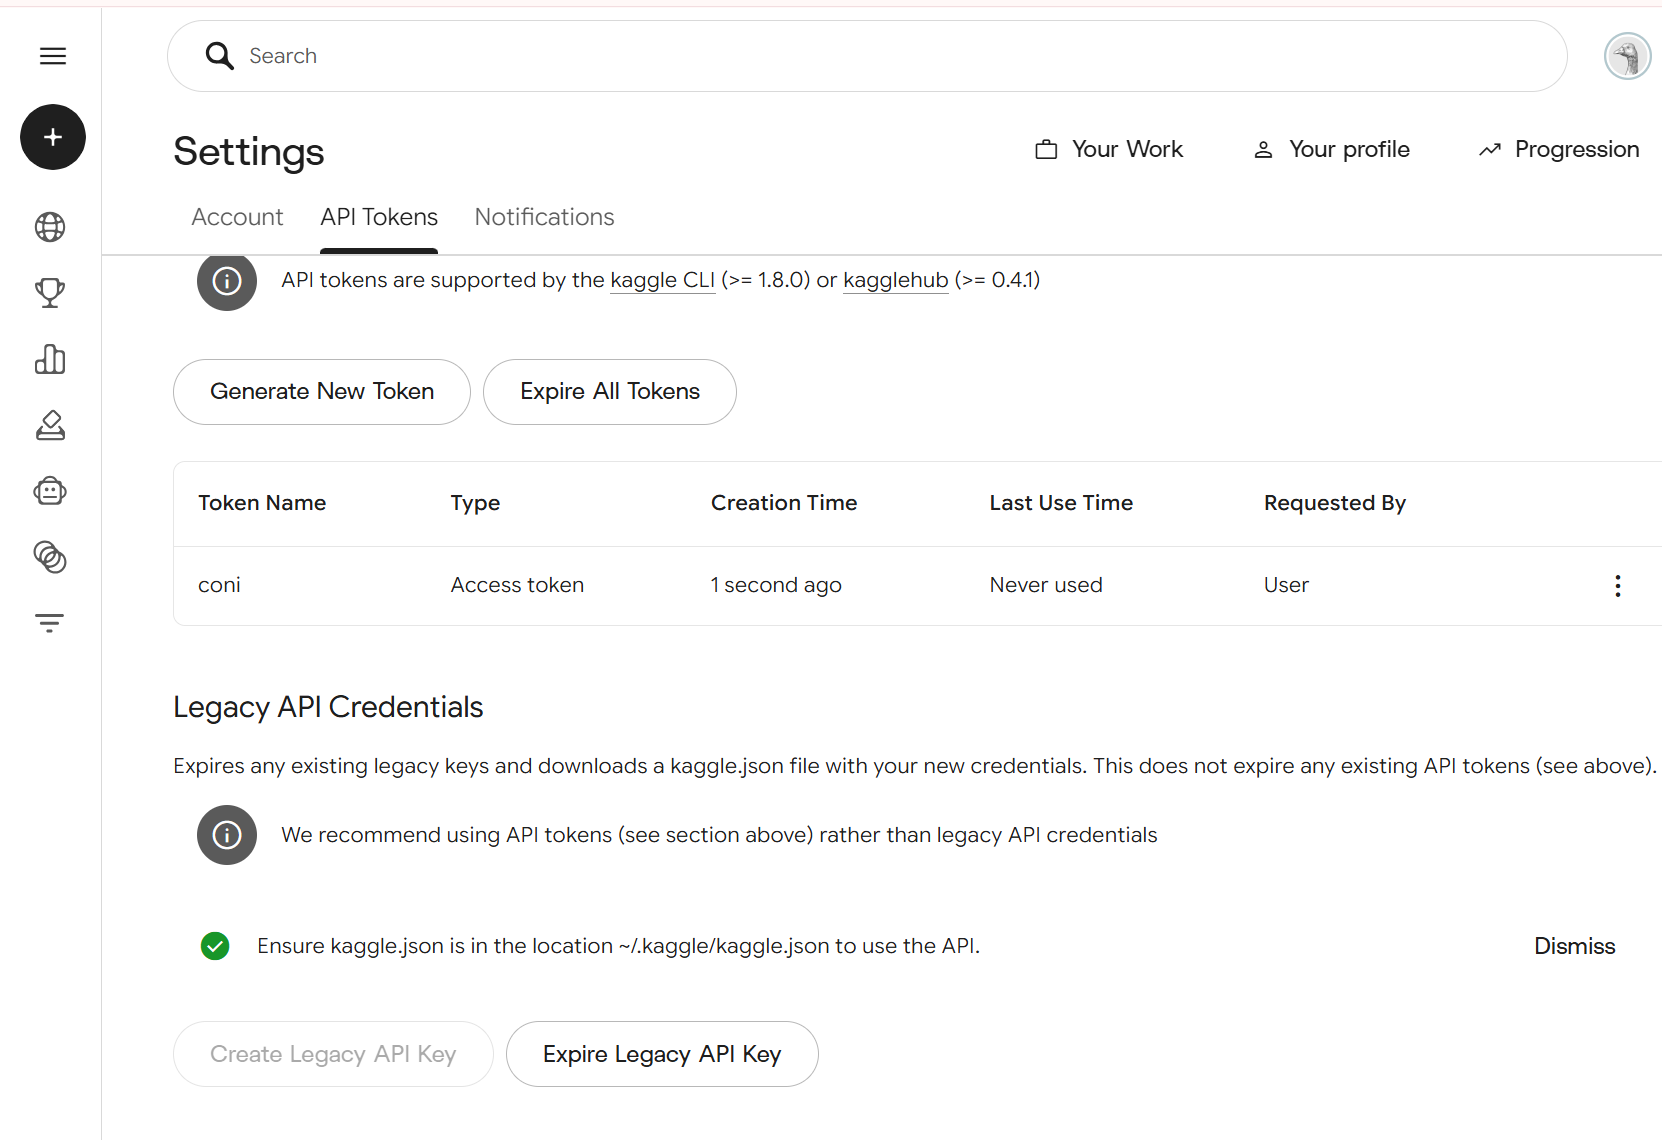

### Kaggle API 키 업로드

In [60]:
#코랩에 다운받은 json 파일 업로드
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (2).json


{'kaggle (2).json': b'{"username":"conikim","key":"67aee15df08d219c21de21b4f429c6b1"}'}

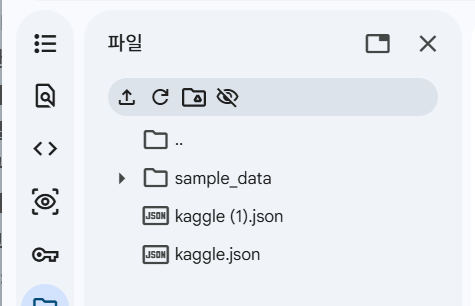

### Kaggle API 키 사용을 위한 Colab 환경 설정

In [61]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

### Kaggle 데이터셋 다운로드

In [65]:
!kaggle competitions download -c store-sales-time-series-forecasting #특정 상점에서 물건 판매된 기록

!unzip store-sales-time-series-forecasting.zip

100% 21.4M/21.4M [00:00<00:00, 127MB/s] 

Archive:  store-sales-time-series-forecasting.zip
  inflating: holidays_events.csv     
  inflating: oil.csv                 
  inflating: sample_submission.csv   
  inflating: stores.csv              
  inflating: test.csv                
  inflating: train.csv               
  inflating: transactions.csv        


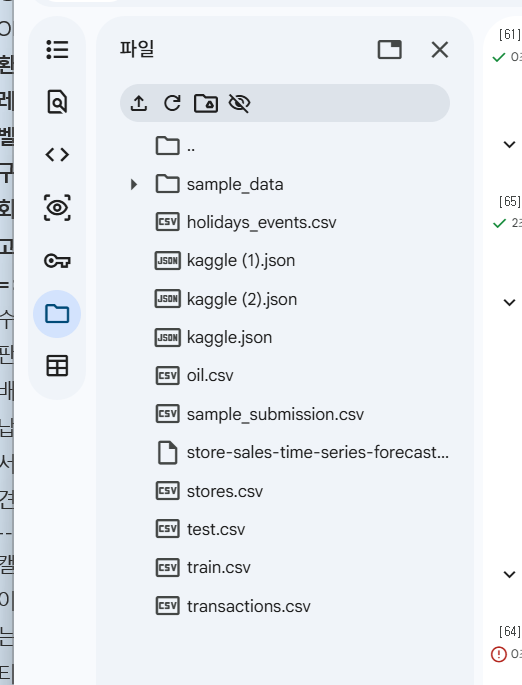

### Kaggle 데이터셋 DataFrame 로드 및 살펴보기

In [71]:
import pandas as pd

#--- Grocery Sales 데이터 DataFrame 로드
train = pd.read_csv('train.csv') #read_cs는 함수니 소괄호로 감싸야 함.
stores = pd.read_csv('stores.csv')
transactions = pd.read_csv('transactions.csv')
oil = pd.read_csv('oil.csv')
holidays_events = pd.read_csv('holidays_events.csv')

#--- 판매 데이터 살펴보기
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


### Kaggle 데이터셋 측정

In [73]:
# 판매 데이터 기본 통계량
train.describe()


,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


In [74]:

# 매장 데이터 기본 정보
stores.head()



,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [75]:
# 원유 가격 데이터 기본 정보
oil.head()

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20
